# PROJECT: RAIN IN AUSTRALIA
**Predict whether it will rain tomorrow (RainTomorrow: Yes = 1, No = 0)**


Sequence:
1. Load the data.
2. Data description.
3. Descriptive analysis.
4. Data visualization.
5. Data preparation (cleaning, removing variables, missing values, rare categories).
6. Feature selection (redundancy check + SelectKBest).
7. Dummy variables, 80/20 split and BALANCING the training set.
8. Model building (five classifiers, 5-fold GridSearchCV).
9. Model performance (metrics, confusion matrix, ROC, comparison).
10. Feature importance.
11. Decision making / recommendations.



In [ ]:
from google.colab import files
uploaded=files.upload()


Saving weatherAUS.csv to weatherAUS.csv


## Libraries

In [ ]:
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats.contingency import association

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, roc_auc_score
)

## SETTINGS — CHANGE VALUES HERE

In [ ]:
MISSING_LIMIT = 35              # Remove a column with more than 35% missing values
RARE_LIMIT = 30                 # Categories with fewer rows become "Other"
REDUNDANCY_THRESHOLD = 0.80     # Drop one input when relationship > 0.80
K_BEST = 10                     # Number of features to keep, or "all"
THRESHOLD = 0.50                # Probability threshold for predicting rain

# The full dataset has about 145,000 rows. SVM and GridSearchCV would take
# hours on all of them, so a random sample is used (as in the diamonds code).
# Set SAMPLE_SIZE = None to use every row (much slower).
SAMPLE_SIZE = 20000

# Balancing method for the TRAINING set: "undersample" or "none".
BALANCING = "undersample"
RANDOM_STATE = 42

OUTPUT_DIR = Path("project_results")
OUTPUT_DIR.mkdir(exist_ok=True)

## 1. LOAD THE DATA

In [ ]:
# read_csv() loads the CSV file into a pandas DataFrame.
df = pd.read_csv("weatherAUS.csv")

## 2. DATA DESCRIPTION

In [ ]:
print("Number of rows and columns:", df.shape)

print("\nFirst five rows:")
print(df.head())

# info() shows data types and the number of non-missing values.
print("\nColumn information:")
df.info()

print("\nMissing values:")
print(df.isna().sum())

print("\nMissing values (%):")
print((df.isna().mean() * 100).round(1).sort_values(ascending=False))

print("\nNumber of duplicated rows:", df.duplicated().sum())

# Number of distinct values in EVERY column.
print("\nNumber of unique values per column:")
print(df.nunique())

# Explore unique values in the columns with few categories.
for column in df.columns:
    if df[column].nunique() <= 50:
        print(column, ":", df[column].unique())

Number of rows and columns: (145460, 23)

First five rows:
         Date Location  MinTemp  MaxTemp  Rainfall  Evaporation  Sunshine  \
0  2008-12-01   Albury     13.4     22.9       0.6          NaN       NaN   
1  2008-12-02   Albury      7.4     25.1       0.0          NaN       NaN   
2  2008-12-03   Albury     12.9     25.7       0.0          NaN       NaN   
3  2008-12-04   Albury      9.2     28.0       0.0          NaN       NaN   
4  2008-12-05   Albury     17.5     32.3       1.0          NaN       NaN   

  WindGustDir  WindGustSpeed WindDir9am  ... Humidity9am  Humidity3pm  \
0           W           44.0          W  ...        71.0         22.0   
1         WNW           44.0        NNW  ...        44.0         25.0   
2         WSW           46.0          W  ...        38.0         30.0   
3          NE           24.0         SE  ...        45.0         16.0   
4           W           41.0        ENE  ...        82.0         33.0   

   Pressure9am  Pressure3pm  Cloud9am  

## 3. DESCRIPTIVE ANALYSIS

In [ ]:
numerical_columns = [
    "MinTemp", "MaxTemp", "Rainfall", "Evaporation", "Sunshine",
    "WindGustSpeed", "WindSpeed9am", "WindSpeed3pm", "Humidity9am",
    "Humidity3pm", "Pressure9am", "Pressure3pm", "Cloud9am", "Cloud3pm",
    "Temp9am", "Temp3pm"
]
categorical_columns = [
    "Location", "WindGustDir", "WindDir9am", "WindDir3pm", "RainToday"
]

# describe() gives the numerical summary statistics.
print("\nNumerical summary:")
print(df[numerical_columns].describe().round(2).T)

# Class balance of the target — this dataset is UNBALANCED.
print("\nTarget distribution (counts):")
print(df["RainTomorrow"].value_counts(dropna=False))
print("\nTarget distribution (%):")
print((df["RainTomorrow"].value_counts(normalize=True) * 100).round(2))

# Average of each numerical feature for rainy and dry next days.
print("\nMean of numerical features by target:")
print(df.groupby("RainTomorrow")[numerical_columns].mean().round(2).T)

# Frequency of each category, and the % No / Yes inside each category.
for column in categorical_columns:
    print("\n", column, "— counts:")
    print(df[column].value_counts())
    print(column, "— % No / Yes rain tomorrow per category:")
    print((pd.crosstab(df[column], df["RainTomorrow"], normalize="index") * 100).round(1))


Numerical summary:
                  count     mean    std    min     25%     50%     75%     max
MinTemp        143975.0    12.19   6.40   -8.5     7.6    12.0    16.9    33.9
MaxTemp        144199.0    23.22   7.12   -4.8    17.9    22.6    28.2    48.1
Rainfall       142199.0     2.36   8.48    0.0     0.0     0.0     0.8   371.0
Evaporation     82670.0     5.47   4.19    0.0     2.6     4.8     7.4   145.0
Sunshine        75625.0     7.61   3.79    0.0     4.8     8.4    10.6    14.5
WindGustSpeed  135197.0    40.04  13.61    6.0    31.0    39.0    48.0   135.0
WindSpeed9am   143693.0    14.04   8.92    0.0     7.0    13.0    19.0   130.0
WindSpeed3pm   142398.0    18.66   8.81    0.0    13.0    19.0    24.0    87.0
Humidity9am    142806.0    68.88  19.03    0.0    57.0    70.0    83.0   100.0
Humidity3pm    140953.0    51.54  20.80    0.0    37.0    52.0    66.0   100.0
Pressure9am    130395.0  1017.65   7.11  980.5  1012.9  1017.6  1022.4  1041.0
Pressure3pm    130432.0  1015.26

## 4. DATA VISUALIZATION

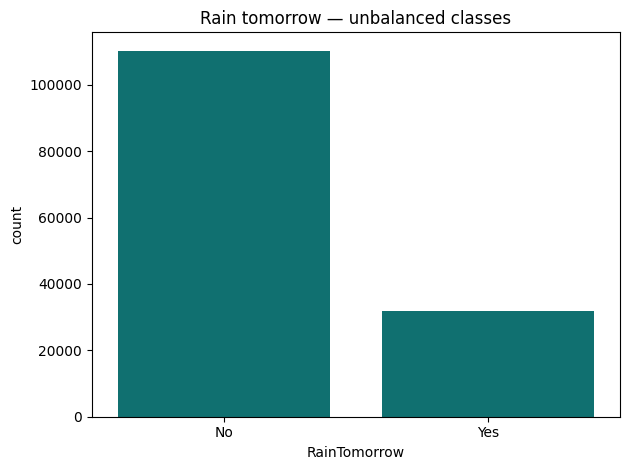

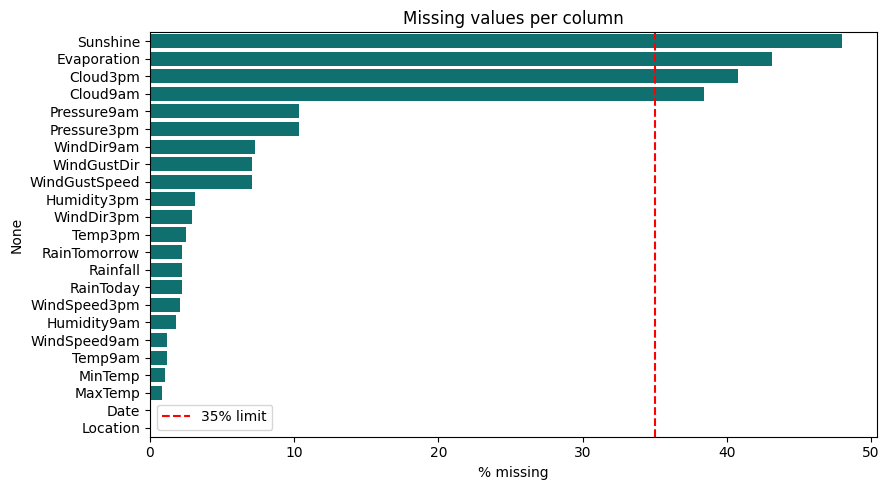

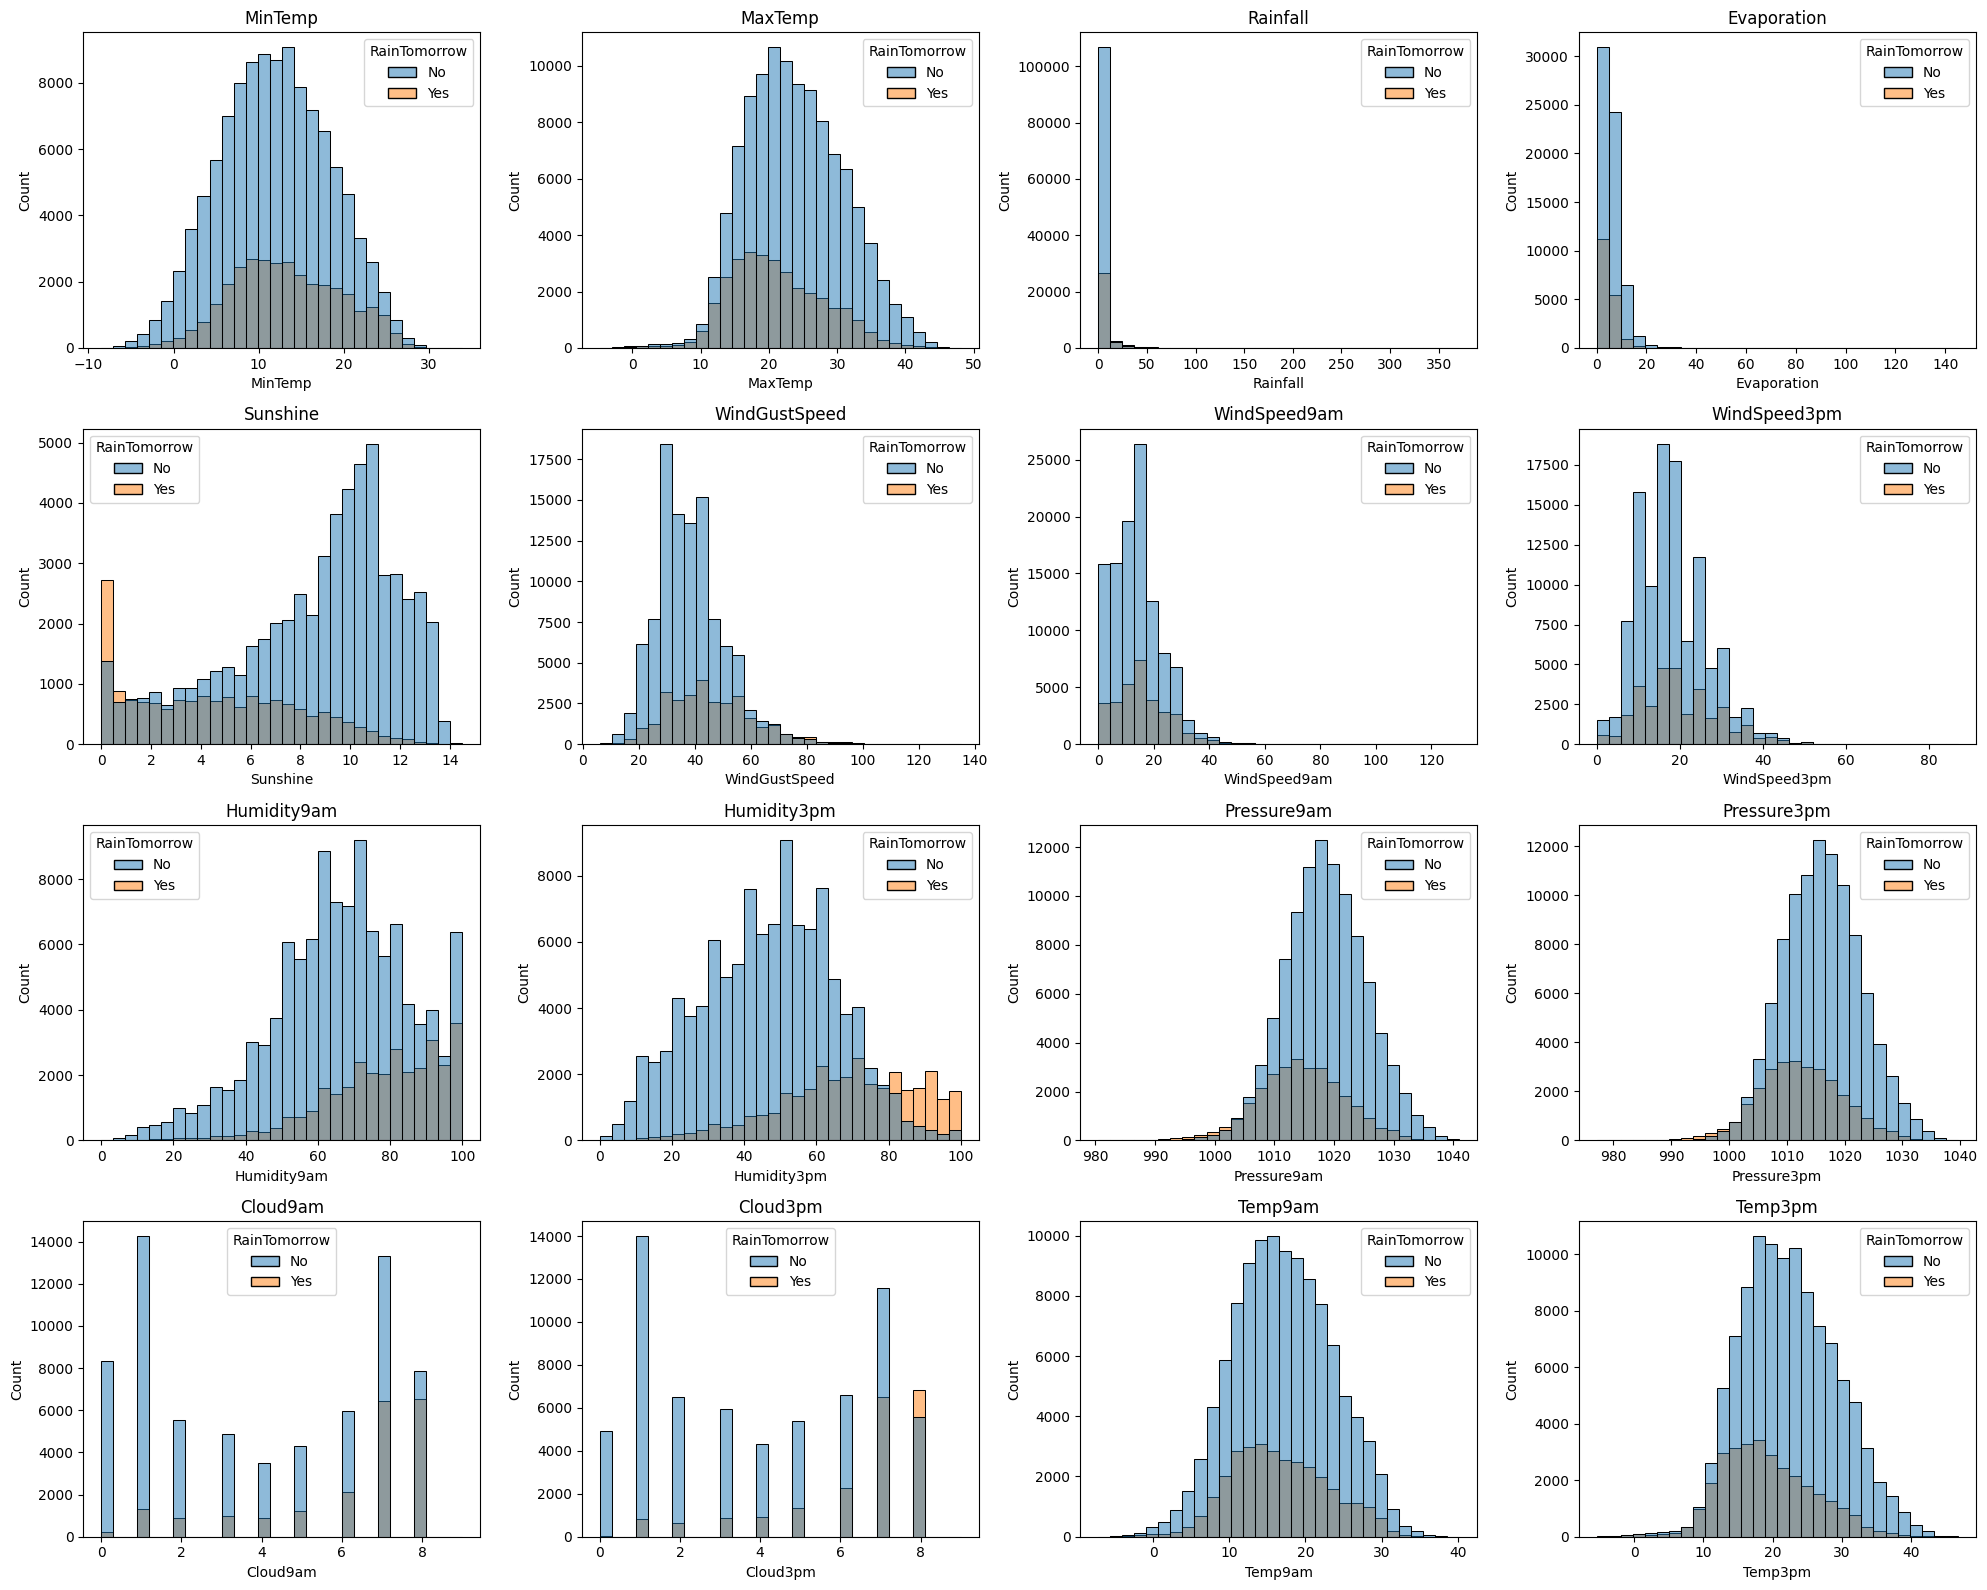

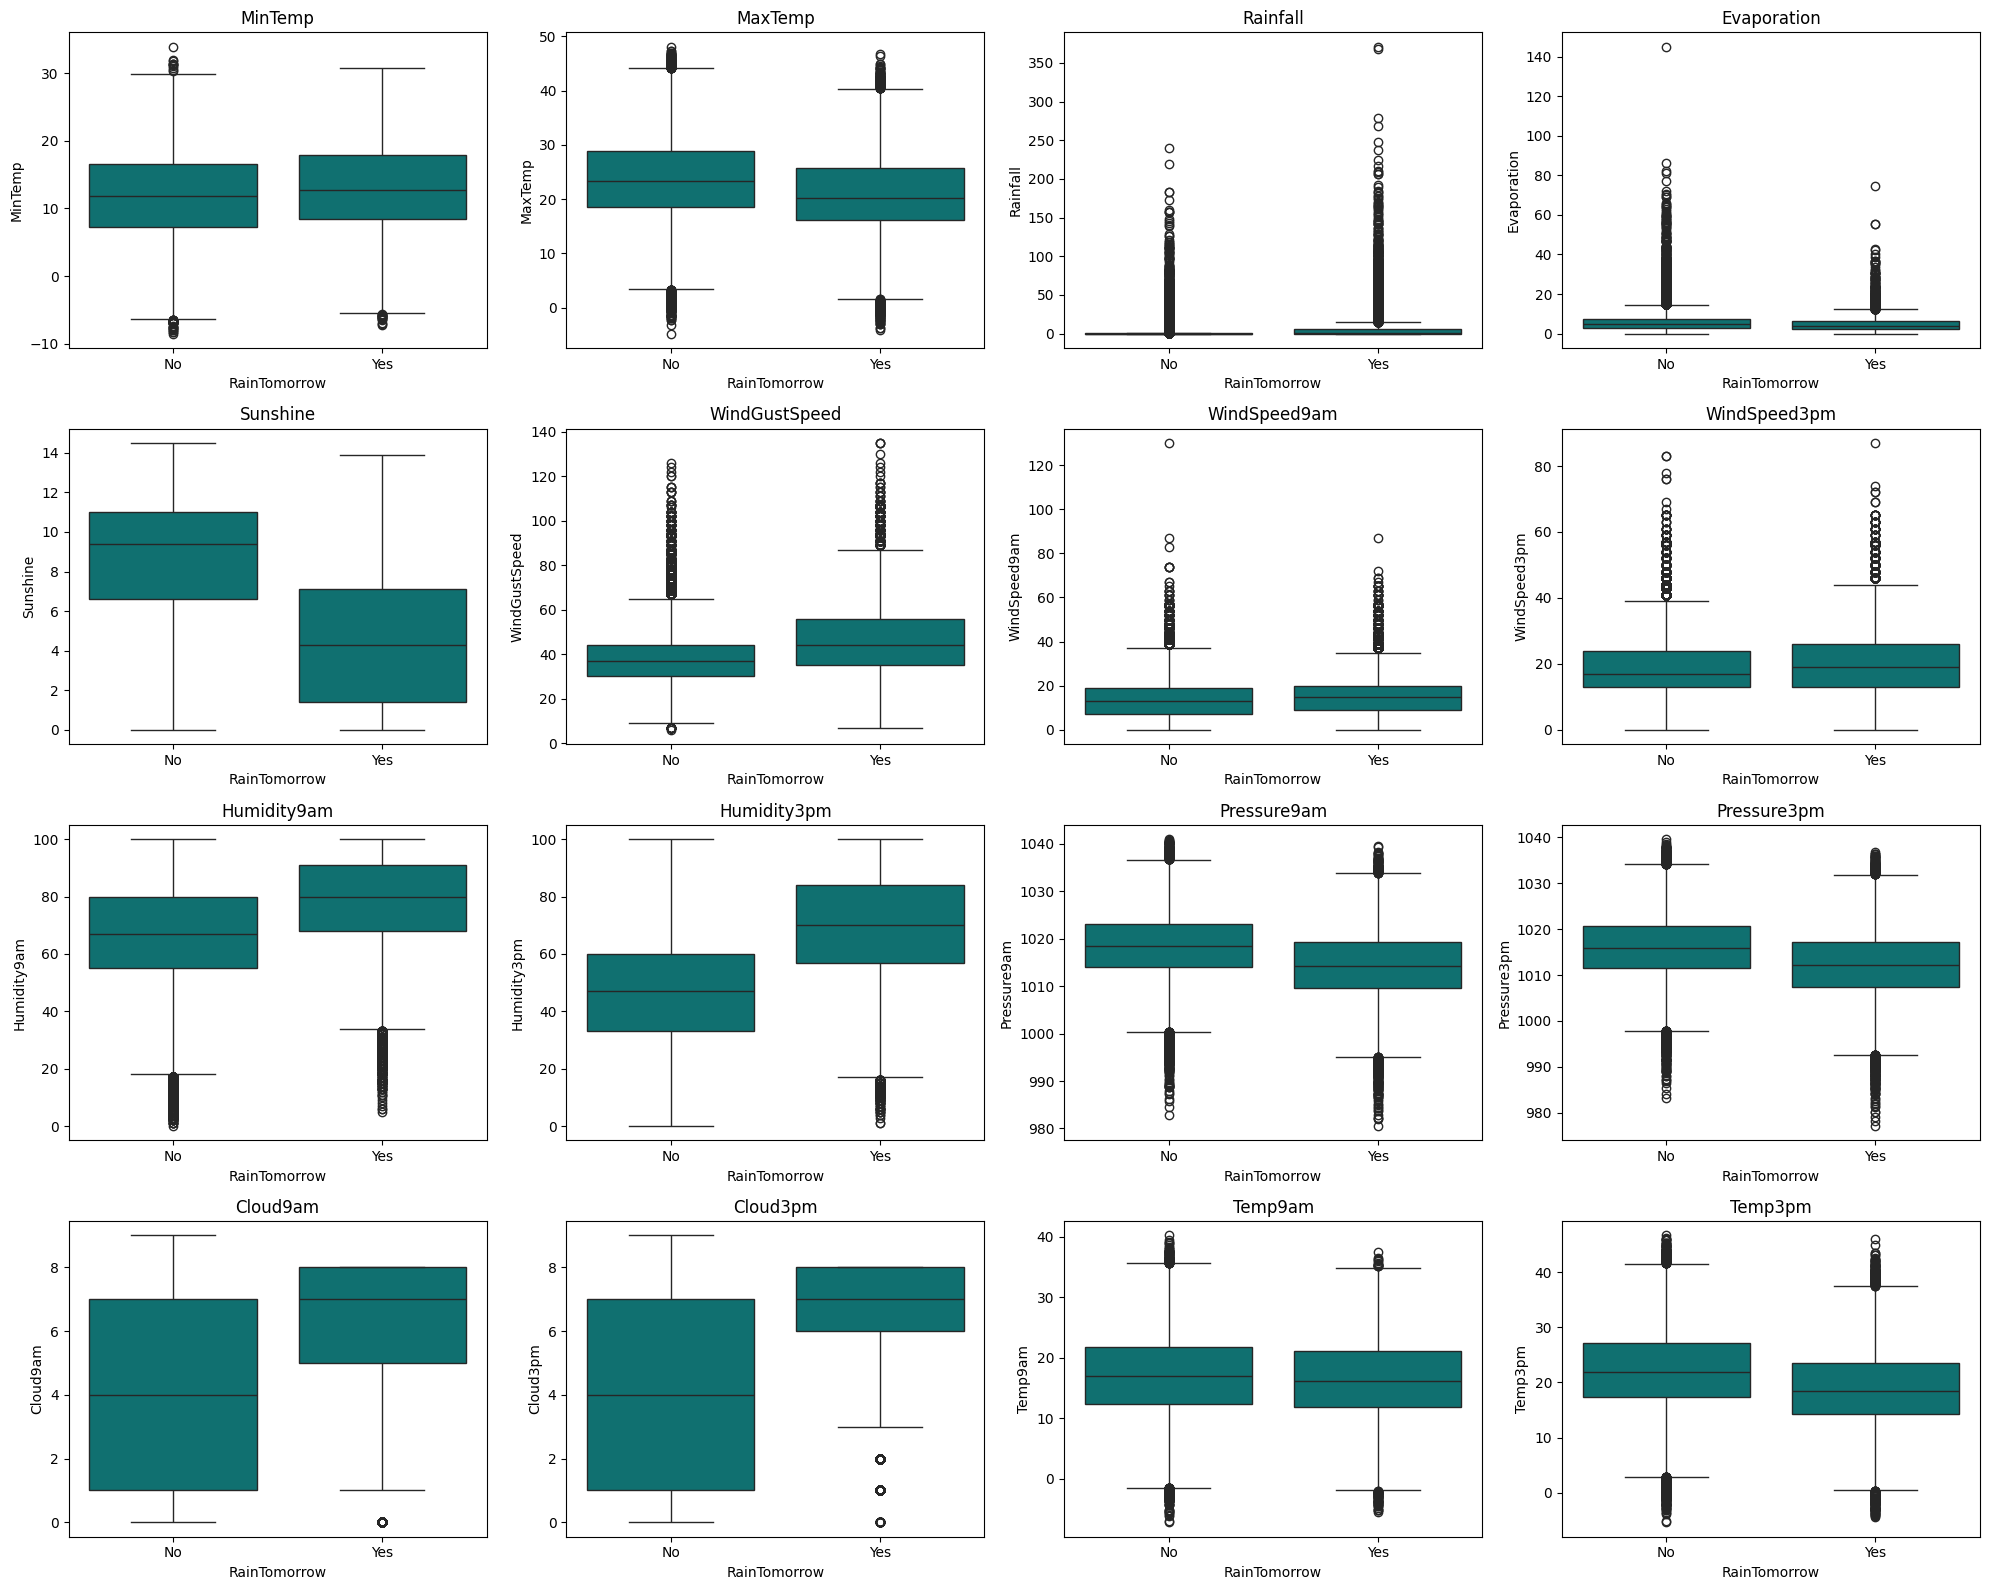

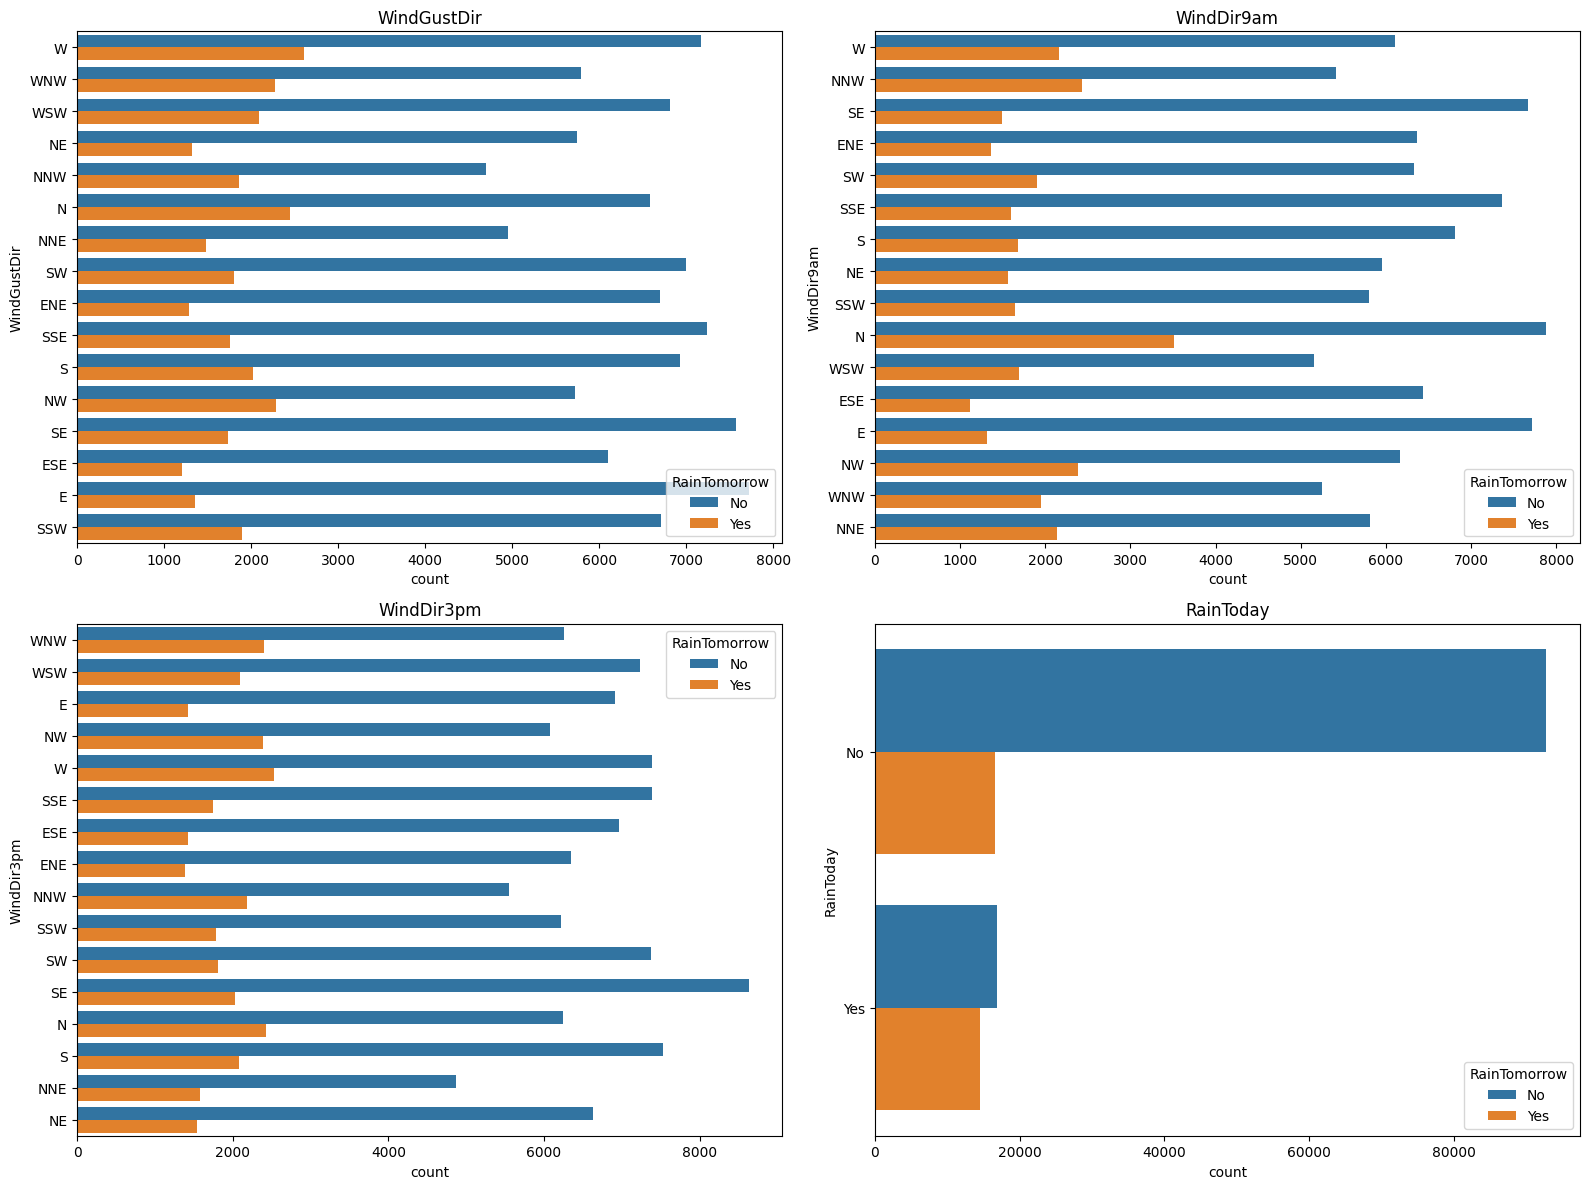

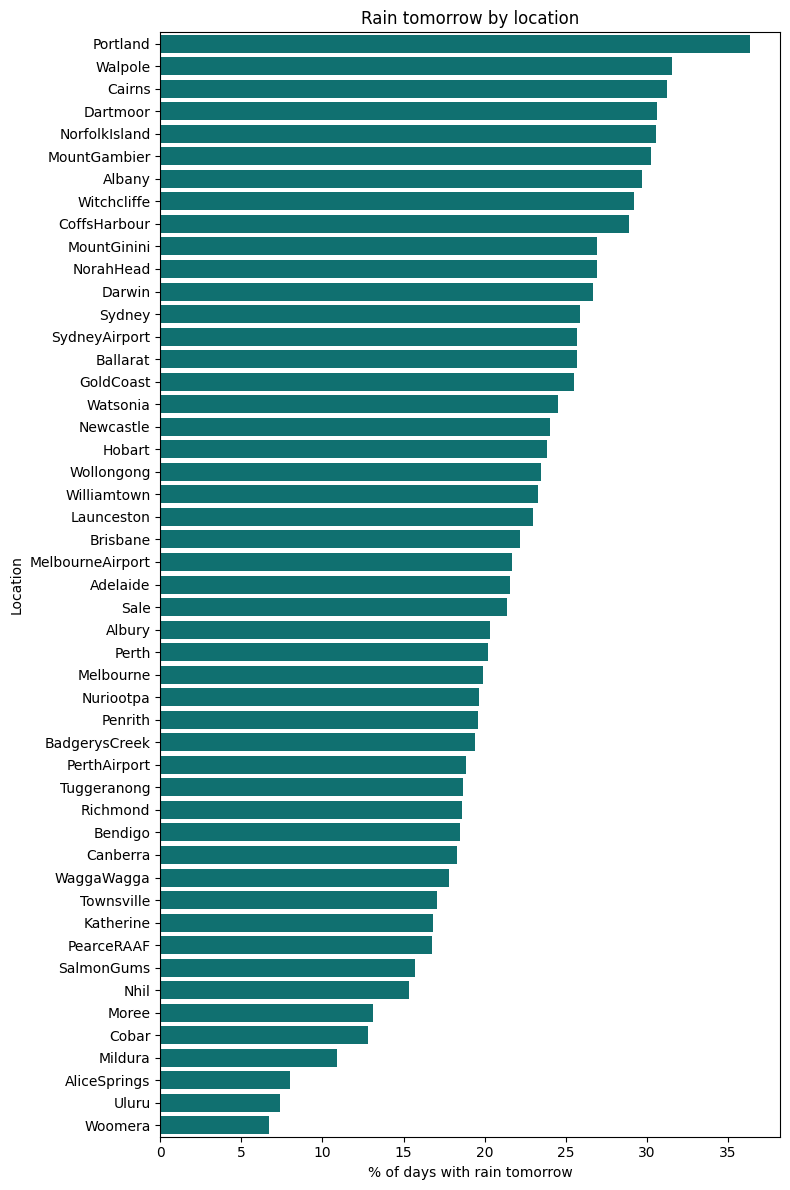

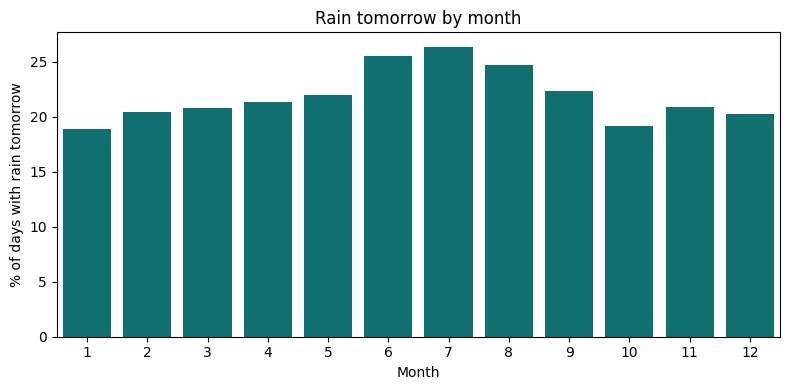

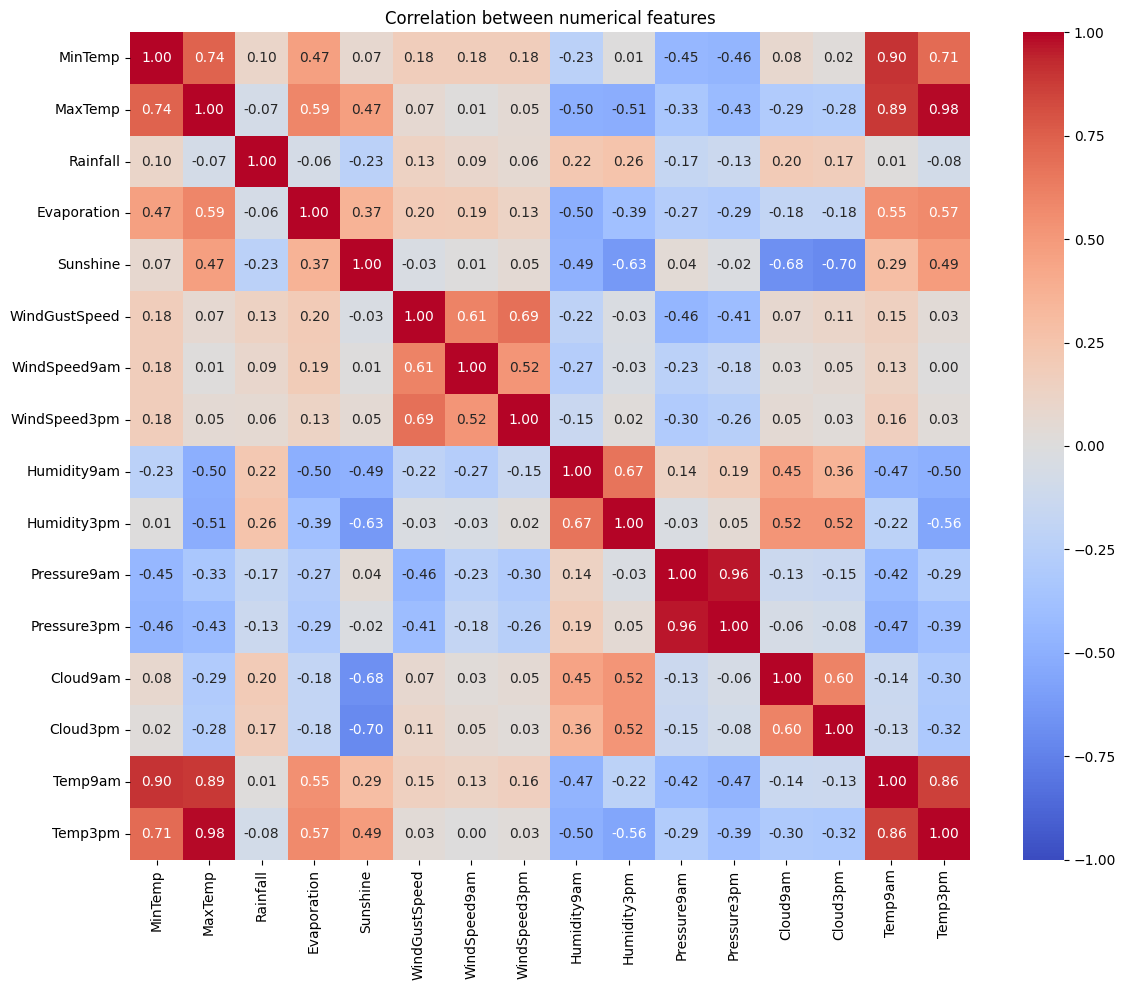

In [ ]:
# Plot the number of rainy and dry next days (shows the imbalance).
sns.countplot(data=df, x="RainTomorrow", color="teal")
plt.title("Rain tomorrow — unbalanced classes")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_target_classes.png", dpi=160)
plt.show()

# Missing values per column.
plt.figure(figsize=(9, 5))
missing = (df.isna().mean() * 100).sort_values(ascending=False)
sns.barplot(x=missing.values, y=missing.index, color="teal")
plt.axvline(MISSING_LIMIT, color="red", linestyle="--", label=f"{MISSING_LIMIT}% limit")
plt.xlabel("% missing")
plt.title("Missing values per column")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_missing_values.png", dpi=160)
plt.show()

# Histograms: distribution of each numerical feature, by target.
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
for ax, column in zip(axes.flatten(), numerical_columns):
    sns.histplot(data=df, x=column, hue="RainTomorrow", bins=30, ax=ax)
    ax.set_title(column)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_histograms_by_target.png", dpi=160)
plt.show()

# Boxplots: compare rainy and dry next days for each numerical feature.
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
for ax, column in zip(axes.flatten(), numerical_columns):
    sns.boxplot(data=df, x="RainTomorrow", y=column, color="teal", ax=ax)
    ax.set_title(column)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_boxplots_by_target.png", dpi=160)
plt.show()

# Countplots: wind directions and RainToday, split by target.
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for ax, column in zip(axes.flatten(), ["WindGustDir", "WindDir9am", "WindDir3pm", "RainToday"]):
    sns.countplot(data=df, y=column, hue="RainTomorrow", ax=ax)
    ax.set_title(column)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_categorical_by_target.png", dpi=160)
plt.show()

# % of rainy next days per location.
rain_by_location = (df.groupby("Location")["RainTomorrow"]
                    .apply(lambda values: (values == "Yes").mean() * 100)
                    .sort_values(ascending=False))
plt.figure(figsize=(8, 12))
sns.barplot(x=rain_by_location.values, y=rain_by_location.index, color="teal")
plt.xlabel("% of days with rain tomorrow")
plt.title("Rain tomorrow by location")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_rain_by_location.png", dpi=160)
plt.show()

# % of rainy next days per month (seasonality).
month = pd.to_datetime(df["Date"]).dt.month
rain_by_month = (df["RainTomorrow"] == "Yes").groupby(month).mean() * 100
plt.figure(figsize=(8, 4))
sns.barplot(x=rain_by_month.index, y=rain_by_month.values, color="teal")
plt.xlabel("Month")
plt.ylabel("% of days with rain tomorrow")
plt.title("Rain tomorrow by month")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "07_rain_by_month.png", dpi=160)
plt.show()

# Correlation heatmap of the numerical features.
plt.figure(figsize=(12, 10))
sns.heatmap(df[numerical_columns].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between numerical features")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "08_correlation_heatmap.png", dpi=160)
plt.show()

## 5. DATA PREPARATION

In [ ]:
# Remove rows that are identical in EVERY column.
df.drop_duplicates(inplace=True)

# We cannot train on a row with an unknown target.
df.dropna(subset=["RainTomorrow"], inplace=True)

# Date is text. Keep the month (season matters for rain), then remove Date.
df["Month"] = pd.to_datetime(df["Date"]).dt.month
df.drop(columns=["Date"], inplace=True)
numerical_columns = numerical_columns + ["Month"]

# Remove columns with too many missing values (more than MISSING_LIMIT %).
# Filling almost half a column with one value would create fake information.
missing_percent = df.isna().mean() * 100
too_many_missing = missing_percent[missing_percent > MISSING_LIMIT].index.tolist()
df.drop(columns=too_many_missing, inplace=True)
numerical_columns = [c for c in numerical_columns if c not in too_many_missing]
print("Removed (more than", MISSING_LIMIT, "% missing):", too_many_missing)

# Random sample to keep training time reasonable.
# stratify keeps the same Yes/No proportion as the full data.
if SAMPLE_SIZE is not None and SAMPLE_SIZE < len(df):
    df, _ = train_test_split(df, train_size=SAMPLE_SIZE,
                             random_state=RANDOM_STATE, stratify=df["RainTomorrow"])
print("Rows used:", len(df))

# X = inputs; y = the answer (rain tomorrow or not).
X = df.drop("RainTomorrow", axis=1)
y = df["RainTomorrow"]

# Encode the target using a FIXED rule: Yes -> 1, No -> 0.
y = y.map({"Yes": 1, "No": 0})

# Binary feature: one 0/1 column.
X["RainToday"] = X["RainToday"].map({"No": 0, "Yes": 1})

# Categories with fewer than RARE_LIMIT observations are combined into "Other".
nominal_columns = ["Location", "WindGustDir", "WindDir9am", "WindDir3pm"]

for column in nominal_columns:
    counts = X[column].value_counts()
    rare_values = counts[counts < RARE_LIMIT].index.tolist()
    if len(rare_values) >= 2:
        X[column] = X[column].replace(rare_values, "Other")
        print(column, ": combined into 'Other' ->", rare_values)
    elif len(rare_values) == 1:
        print(column, ": only one rare value, kept as it is ->", rare_values)
    else:
        print(column, ": no category below", RARE_LIMIT, "observations")

# Fill missing values.
# SIMPLIFIED (as in Code 1): replacements are calculated once, before splitting.
# Mode = most frequent value; suitable for categories and RainToday.
for column in nominal_columns + ["RainToday"]:
    X[column] = X[column].fillna(X[column].mode()[0])

# Median = middle value; useful for numerical features with outliers.
for column in numerical_columns:
    X[column] = X[column].fillna(X[column].median())

print("\nMissing values after preparation:")
print(X.isna().sum())

print("\nPrepared features (first five rows):")
print(X.head())

Removed (more than 35 % missing): ['Evaporation', 'Sunshine', 'Cloud9am', 'Cloud3pm']
Rows used: 20000
Location : no category below 30 observations
WindGustDir : no category below 30 observations
WindDir9am : no category below 30 observations
WindDir3pm : no category below 30 observations

Missing values after preparation:
Location         0
MinTemp          0
MaxTemp          0
Rainfall         0
WindGustDir      0
WindGustSpeed    0
WindDir9am       0
WindDir3pm       0
WindSpeed9am     0
WindSpeed3pm     0
Humidity9am      0
Humidity3pm      0
Pressure9am      0
Pressure3pm      0
Temp9am          0
Temp3pm          0
RainToday        0
Month            0
dtype: int64

Prepared features (first five rows):
         Location  MinTemp  MaxTemp  Rainfall WindGustDir  WindGustSpeed  \
141034     Darwin     26.9     34.1       0.0          NW           33.0   
46241    Canberra     -1.6     15.2       0.0           W           39.0   
28721    Richmond      2.1     17.9       0.2         

## 6. FEATURE SELECTION

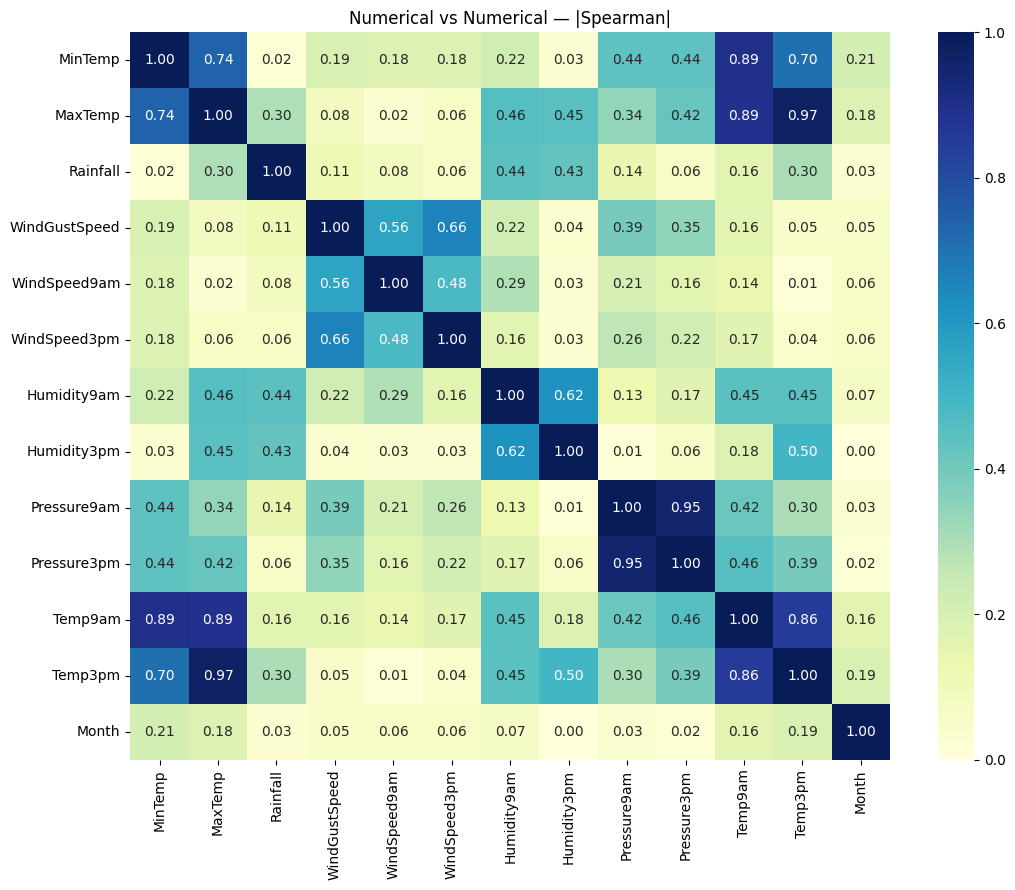

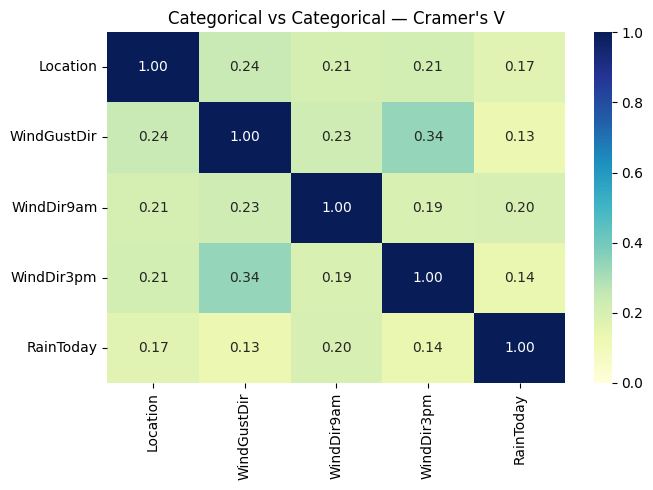

Redundant: DROP Temp3pm — KEEP MaxTemp ( 0.974 )
Redundant: DROP Pressure3pm — KEEP Pressure9am ( 0.954 )
Redundant: DROP Temp9am — KEEP MinTemp ( 0.895 )

Features after redundancy check: ['Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'RainToday', 'Month']


In [ ]:
# A. RELATIONSHIPS BETWEEN INPUT FEATURES (REDUNDANCY CHECK)
# Numerical vs numerical: absolute Spearman correlation.
# Categorical vs categorical: Cramer's V (based on Chi-squared).
# All scores range from 0 (weak) to 1 (strong).
numeric_features = numerical_columns
categorical_features = nominal_columns + ["RainToday"]

spearman = X[numeric_features].corr(method="spearman").abs()

cramer = pd.DataFrame(np.eye(len(categorical_features)),
                      index=categorical_features, columns=categorical_features)
for a in categorical_features:
    for b in categorical_features:
        if a != b:
            table = pd.crosstab(X[a], X[b])
            cramer.loc[a, b] = association(table.to_numpy(), method="cramer")

plt.figure(figsize=(11, 9))
sns.heatmap(spearman, annot=True, fmt=".2f", vmin=0, vmax=1, cmap="YlGnBu")
plt.title("Numerical vs Numerical — |Spearman|")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "09_spearman_heatmap.png", dpi=160)
plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(cramer, annot=True, fmt=".2f", vmin=0, vmax=1, cmap="YlGnBu")
plt.title("Categorical vs Categorical — Cramer's V")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "10_cramers_v_heatmap.png", dpi=160)
plt.show()

# Check the strongest relationships first.
# For each pair above the threshold, drop the second feature of the pair.
pairs = []
for matrix in [spearman, cramer]:
    columns = matrix.columns.tolist()
    for i, a in enumerate(columns):
        for b in columns[i + 1:]:
            pairs.append([a, b, matrix.loc[a, b]])
pairs = sorted(pairs, key=lambda pair: pair[2], reverse=True)

retained = X.columns.tolist()
for a, b, score in pairs:
    if score > REDUNDANCY_THRESHOLD and a in retained and b in retained:
        retained.remove(b)
        print("Redundant: DROP", b, "— KEEP", a, "(", round(score, 3), ")")

print("\nFeatures after redundancy check:", retained)


SELECTKBEST (Mutual Information), K = 10
      Feature  Mutual Information  Selected
  Humidity3pm              0.1083      True
     Rainfall              0.0508      True
    RainToday              0.0422      True
  Humidity9am              0.0384      True
WindGustSpeed              0.0273      True
  Pressure9am              0.0272      True
     Location              0.0146      True
      MaxTemp              0.0133      True
      MinTemp              0.0080      True
   WindDir9am              0.0066      True
  WindGustDir              0.0060     False
 WindSpeed9am              0.0056     False
   WindDir3pm              0.0046     False
 WindSpeed3pm              0.0043     False
        Month              0.0017     False

FEATURES SELECTED FOR ALL CLASSIFIERS: ['Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'WindGustSpeed', 'WindDir9am', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'RainToday']


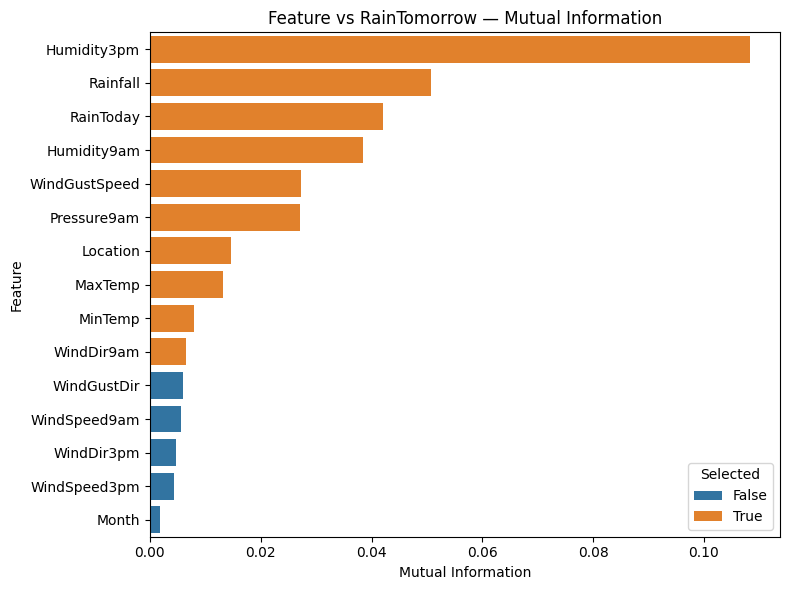

In [ ]:
# B. SELECTKBEST: RELATIONSHIP BETWEEN EACH INPUT AND THE TARGET
# Mutual Information handles both numerical and categorical inputs.
# Category names are converted to integer codes for scoring ONLY.
X_scores = X[retained].copy()
for column in nominal_columns:
    if column in retained:
        X_scores[column] = pd.Categorical(X_scores[column]).codes

# Tell Mutual Information which inputs are discrete (categories / months).
is_discrete = [column in categorical_features or column == "Month" for column in retained]
scoring = partial(mutual_info_classif, discrete_features=is_discrete,
                  random_state=RANDOM_STATE)

number_to_keep = "all" if K_BEST == "all" else min(K_BEST, len(retained))
selector = SelectKBest(score_func=scoring, k=number_to_keep)
selector.fit(X_scores, y)
chosen_features = X_scores.columns[selector.get_support()].tolist()

ranking = pd.DataFrame({
    "Feature": retained,
    "Mutual Information": selector.scores_,
    "Selected": selector.get_support()
}).sort_values("Mutual Information", ascending=False)
ranking.to_csv(OUTPUT_DIR / "selectkbest_scores.csv", index=False)

print("\nSELECTKBEST (Mutual Information), K =", K_BEST)
print(ranking.round(4).to_string(index=False))
print("\nFEATURES SELECTED FOR ALL CLASSIFIERS:", chosen_features)

plt.figure(figsize=(8, 6))
sns.barplot(data=ranking, x="Mutual Information", y="Feature",
            hue="Selected", dodge=False)
plt.title("Feature vs RainTomorrow — Mutual Information")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "11_mutual_information.png", dpi=160)
plt.show()

## 7. DUMMY VARIABLES, 80/20 SPLIT AND BALANCING

In [ ]:
# Only the selected features are kept.
X = X[chosen_features]

# Nominal features (names, no order) become one 0/1 column per category.
# get_dummies() also removes the original text columns automatically.
dummy_columns = [c for c in nominal_columns if c in chosen_features]
X = pd.get_dummies(X, columns=dummy_columns, dtype=int)

print("\nFinal features after dummy encoding:", X.shape[1])
print(X.head())

# Train on 80%; evaluate on the remaining 20%.
# stratify=y keeps approximately the same Yes/No balance in each set.
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# Keep a copy of the unbalanced training set to show the effect of balancing later.
X_train_unbalanced = X_train.copy()
y_train_unbalanced = y_train.copy()

print("\nTraining classes BEFORE balancing:")
print(y_train.value_counts())


Final features after dummy encoding: 73
        MinTemp  MaxTemp  Rainfall  WindGustSpeed  Humidity9am  Humidity3pm  \
141034     26.9     34.1       0.0           33.0         69.0         58.0   
46241      -1.6     15.2       0.0           39.0         83.0         57.0   
28721       2.1     17.9       0.2           15.0        100.0         53.0   
76167       9.5     13.6      12.8           46.0         65.0         59.0   
105280      6.8     18.7       0.1           44.0         53.0         55.0   

        Pressure9am  RainToday  Location_Adelaide  Location_Albany  ...  \
141034       1009.6        0.0                  0                0  ...   
46241        1017.6        0.0                  0                0  ...   
28721        1025.6        0.0                  0                0  ...   
76167        1028.2        1.0                  0                0  ...   
105280       1014.8        0.0                  0                0  ...   

        WindDir9am_NNW  WindDir9a

### Balancing the training set (random undersampling)


Training classes AFTER balancing:
target
0    3587
1    3587
Name: count, dtype: int64


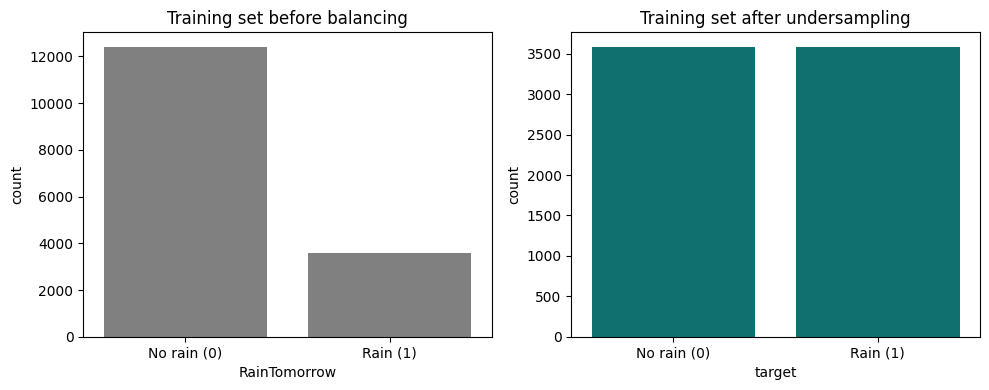


Dataset sizes:
Training (balanced): 7174
Validation (real proportions): 4000


In [ ]:
# BALANCING — RANDOM UNDERSAMPLING (TRAINING SET ONLY)
# Only about 22% of days are followed by rain. A model trained on this
# can reach ~78% accuracy by always predicting "No rain", and it will
# miss many rainy days. Undersampling randomly keeps only as many
# "No" days as there are "Yes" days, so the model sees 50% / 50%.
# - Only the TRAINING set is balanced; the validation set keeps the real
#   proportions, so the results reflect real-life performance.
# - Undersampling (not oversampling) is used because the data is large,
#   and copied rows from oversampling could appear in both the training
#   and the validation folds of cross-validation.
if BALANCING == "undersample":
    train = X_train.copy()
    train["target"] = y_train

    rain = train[train["target"] == 1]
    no_rain = train[train["target"] == 0].sample(n=len(rain), random_state=RANDOM_STATE)

    train = pd.concat([rain, no_rain]).sample(frac=1, random_state=RANDOM_STATE)
    X_train = train.drop("target", axis=1)
    y_train = train["target"]

print("\nTraining classes AFTER balancing:")
print(y_train.value_counts())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x=y_train_unbalanced, ax=axes[0], color="gray")
axes[0].set_title("Training set before balancing")
sns.countplot(x=y_train, ax=axes[1], color="teal")
axes[1].set_title("Training set after undersampling")
for ax in axes:
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No rain (0)", "Rain (1)"])
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "12_balancing.png", dpi=160)
plt.show()

print("\nDataset sizes:")
print("Training (balanced):", len(X_train))
print("Validation (real proportions):", len(X_val))

## 8. MODEL BUILDING — FIVE CLASSIFIERS WITH GRID SEARCH

In [ ]:
# Hyperparameters are settings chosen before a model is fitted.
# The prefix "model__" refers to the classifier inside the Pipeline.
models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000),
        {"model__C": [0.1, 1, 10]}
    ),
    "SVM": (
        SVC(probability=True),
        {"model__C": [0.1, 1, 10], "model__gamma": ["scale", "auto"]}
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {"model__max_depth": [3, 5, None], "model__min_samples_leaf": [1, 5]}
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42),
        {"model__n_estimators": [100, 200], "model__max_depth": [5, None]}
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=42),
        {"model__n_estimators": [100, 200], "model__learning_rate": [0.05, 0.1]}
    )
}

# Five folds: train on four parts and validate on the fifth.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

validation_results = []
best_models = {}
best_model_name = None
best_validation_auc = -1

## 9. MODEL PERFORMANCE


MODEL: Logistic Regression
Best hyperparameters: {'model__C': 1}
Average 5-fold CV AUC: 0.84
Fold 1 CV AUC: 0.853
Fold 2 CV AUC: 0.835
Fold 3 CV AUC: 0.834
Fold 4 CV AUC: 0.842
Fold 5 CV AUC: 0.834
Validation accuracy: 78.03 %
Validation precision (Rain): 50.69 %
Validation recall (Rain): 74.02 %
Validation F1-score (Rain): 60.17 %
Validation ROC AUC: 0.853
Validation confusion matrix:
 [[2457  646]
 [ 233  664]]


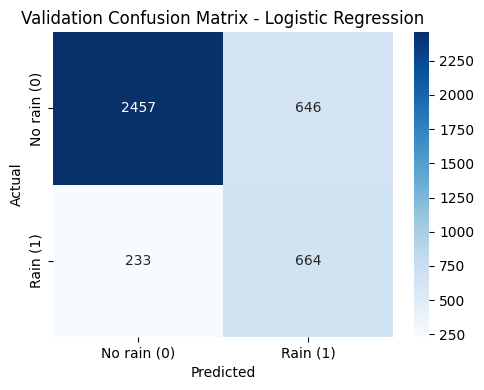

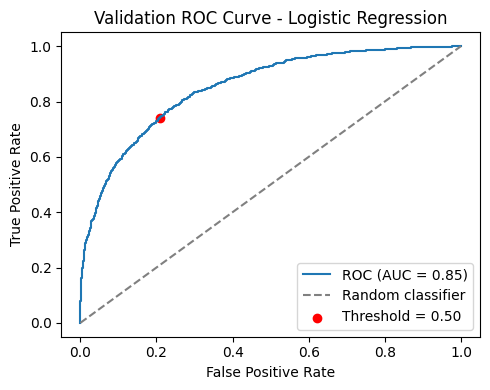


MODEL: SVM
Best hyperparameters: {'model__C': 1, 'model__gamma': 'scale'}
Average 5-fold CV AUC: 0.848
Fold 1 CV AUC: 0.85
Fold 2 CV AUC: 0.853
Fold 3 CV AUC: 0.842
Fold 4 CV AUC: 0.851
Fold 5 CV AUC: 0.844
Validation accuracy: 79.17 %
Validation precision (Rain): 52.43 %
Validation recall (Rain): 77.03 %
Validation F1-score (Rain): 62.39 %
Validation ROC AUC: 0.86
Validation confusion matrix:
 [[2476  627]
 [ 206  691]]


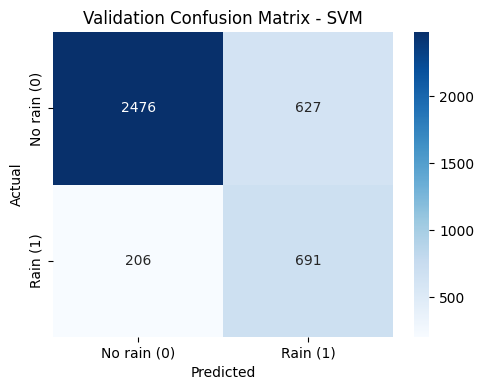

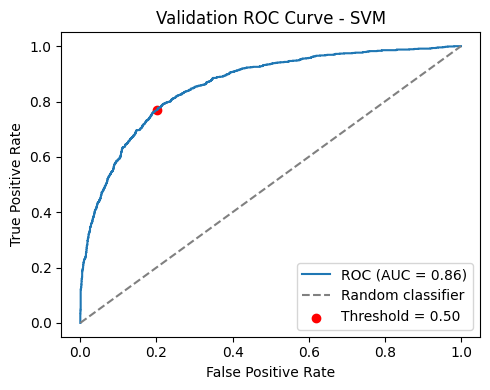


MODEL: Decision Tree
Best hyperparameters: {'model__max_depth': 5, 'model__min_samples_leaf': 5}
Average 5-fold CV AUC: 0.805
Fold 1 CV AUC: 0.817
Fold 2 CV AUC: 0.798
Fold 3 CV AUC: 0.793
Fold 4 CV AUC: 0.813
Fold 5 CV AUC: 0.805
Validation accuracy: 76.08 %
Validation precision (Rain): 47.75 %
Validation recall (Rain): 71.13 %
Validation F1-score (Rain): 57.14 %
Validation ROC AUC: 0.815
Validation confusion matrix:
 [[2405  698]
 [ 259  638]]


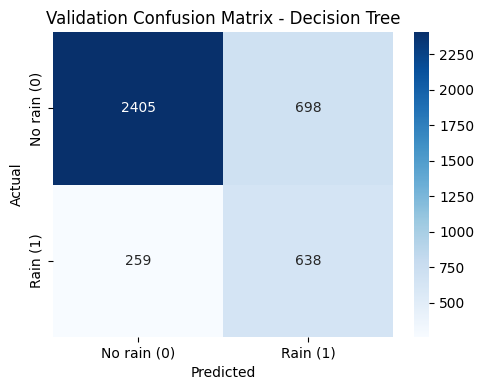

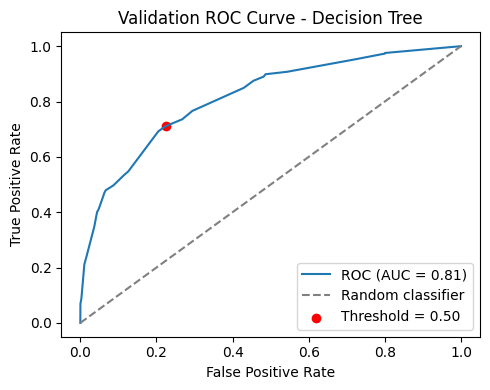


MODEL: Random Forest
Best hyperparameters: {'model__max_depth': None, 'model__n_estimators': 200}
Average 5-fold CV AUC: 0.846
Fold 1 CV AUC: 0.851
Fold 2 CV AUC: 0.842
Fold 3 CV AUC: 0.842
Fold 4 CV AUC: 0.851
Fold 5 CV AUC: 0.846
Validation accuracy: 78.45 %
Validation precision (Rain): 51.32 %
Validation recall (Rain): 76.03 %
Validation F1-score (Rain): 61.28 %
Validation ROC AUC: 0.858
Validation confusion matrix:
 [[2456  647]
 [ 215  682]]


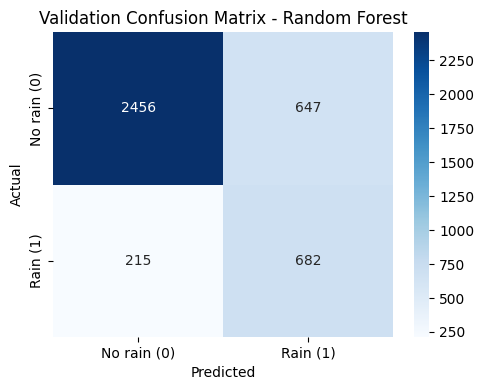

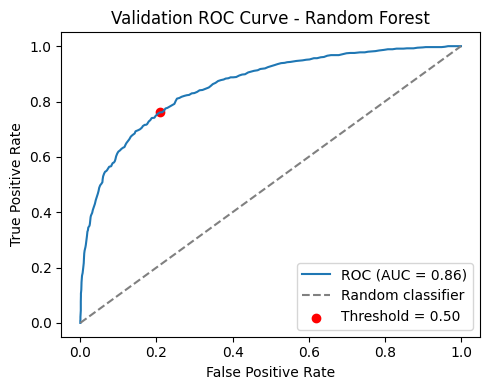


MODEL: Gradient Boosting
Best hyperparameters: {'model__learning_rate': 0.1, 'model__n_estimators': 200}
Average 5-fold CV AUC: 0.849
Fold 1 CV AUC: 0.86
Fold 2 CV AUC: 0.843
Fold 3 CV AUC: 0.843
Fold 4 CV AUC: 0.853
Fold 5 CV AUC: 0.845
Validation accuracy: 78.03 %
Validation precision (Rain): 50.69 %
Validation recall (Rain): 74.14 %
Validation F1-score (Rain): 60.21 %
Validation ROC AUC: 0.853
Validation confusion matrix:
 [[2456  647]
 [ 232  665]]


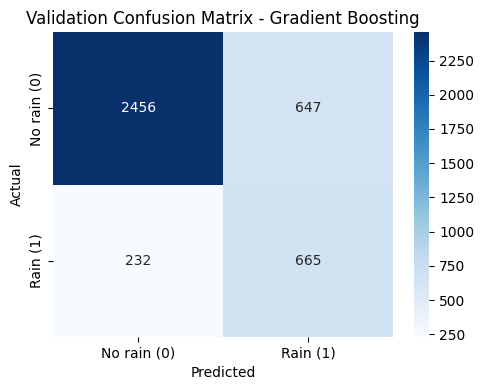

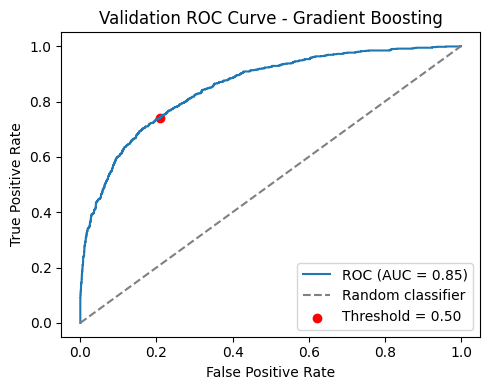

In [ ]:
# With unbalanced data, accuracy alone is misleading:
# always saying "No rain" already gives about 78% accuracy.
# Recall, precision, F1 and AUC for the "Rain" class are more useful.

for name, (classifier, parameter_grid) in models.items():
    print("\nMODEL:", name)

    # The scaler is inside the Pipeline, so it is fitted on training folds only.
    model_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", classifier)
    ])

    grid = GridSearchCV(
        model_pipeline, parameter_grid, cv=cv,
        scoring="roc_auc", refit=True, n_jobs=-1
    )
    grid.fit(X_train, y_train)
    best_models[name] = grid.best_estimator_

    print("Best hyperparameters:", grid.best_params_)
    print("Average 5-fold CV AUC:", round(grid.best_score_, 3))
    for fold in range(5):
        fold_score = grid.cv_results_[f"split{fold}_test_score"][grid.best_index_]
        print("Fold", fold + 1, "CV AUC:", round(fold_score, 3))

    # [:, 1] selects the estimated probability of class 1 (Rain).
    probabilities = grid.best_estimator_.predict_proba(X_val)[:, 1]
    predictions = (probabilities >= THRESHOLD).astype(int)

    accuracy = accuracy_score(y_val, predictions)
    precision = precision_score(y_val, predictions, zero_division=0)
    recall = recall_score(y_val, predictions, zero_division=0)
    f1 = f1_score(y_val, predictions, zero_division=0)
    auc = roc_auc_score(y_val, probabilities)

    print("Validation accuracy:", round(accuracy * 100, 2), "%")
    print("Validation precision (Rain):", round(precision * 100, 2), "%")
    print("Validation recall (Rain):", round(recall * 100, 2), "%")
    print("Validation F1-score (Rain):", round(f1 * 100, 2), "%")
    print("Validation ROC AUC:", round(auc, 3))

    # Confusion matrix: rows = actual labels, columns = predictions.
    cm = confusion_matrix(y_val, predictions, labels=[0, 1])
    print("Validation confusion matrix:\n", cm)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["No rain (0)", "Rain (1)"],
                yticklabels=["No rain (0)", "Rain (1)"])
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("Validation Confusion Matrix - " + name)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / (name.replace(" ", "_") + "_confusion_matrix.png"), dpi=160)
    plt.show()

    # ROC curve: evaluate ALL probability thresholds, not just THRESHOLD.
    fpr, tpr, _ = roc_curve(y_val, probabilities)
    plt.figure(figsize=(5, 4))
    plt.plot(fpr, tpr, label=f"ROC (AUC = {auc:.2f})")
    plt.plot([0, 1], [0, 1], "--", color="gray", label="Random classifier")
    plt.scatter(cm[0, 1] / sum(cm[0]), recall, color="red",
                label=f"Threshold = {THRESHOLD:.2f}")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Validation ROC Curve - " + name)
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / (name.replace(" ", "_") + "_roc_curve.png"), dpi=160)
    plt.show()

    validation_results.append([name, grid.best_score_, auc, accuracy, precision, recall, f1])

    # The highest validation AUC determines the selected classifier.
    if auc > best_validation_auc:
        best_validation_auc = auc
        best_model_name = name


VALIDATION COMPARISON:
              Model  CV AUC  Validation AUC  Accuracy  Precision  Recall  F1-score
Logistic Regression   0.840           0.853     0.780      0.507   0.740     0.602
                SVM   0.848           0.860     0.792      0.524   0.770     0.624
      Decision Tree   0.805           0.815     0.761      0.478   0.711     0.571
      Random Forest   0.846           0.858     0.784      0.513   0.760     0.613
  Gradient Boosting   0.849           0.853     0.780      0.507   0.741     0.602

Selected model: SVM


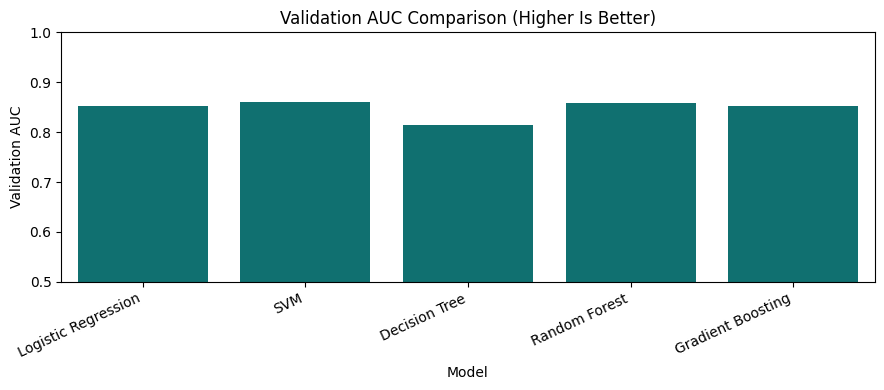

In [ ]:
# Final comparison of all five classifiers.
results_df = pd.DataFrame(
    validation_results,
    columns=["Model", "CV AUC", "Validation AUC", "Accuracy",
             "Precision", "Recall", "F1-score"]
)
results_df.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)

print("\nVALIDATION COMPARISON:")
print(results_df.round(3).to_string(index=False))
print("\nSelected model:", best_model_name)

plt.figure(figsize=(9, 4))
sns.barplot(data=results_df, x="Model", y="Validation AUC", color="teal")
plt.ylim(0.5, 1)
plt.title("Validation AUC Comparison (Higher Is Better)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "13_model_comparison.png", dpi=160)
plt.show()

### Effect of balancing


EFFECT OF BALANCING — SVM
     Training data  Accuracy  Precision  Recall  F1-score
 Without balancing     0.843      0.728   0.478     0.577
With undersampling     0.792      0.524   0.770     0.624


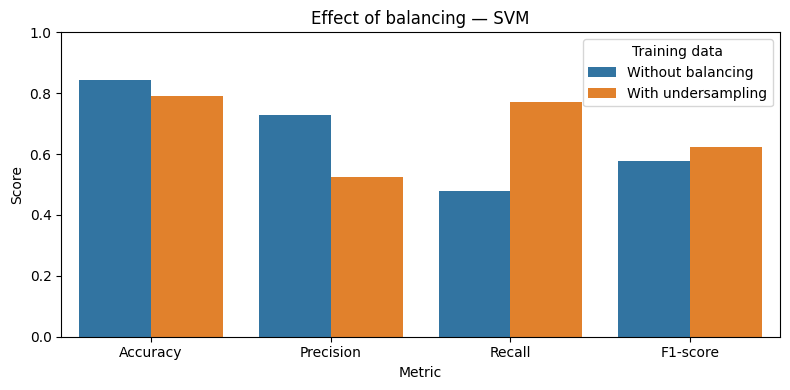

In [ ]:
# EFFECT OF BALANCING
# The selected model, with the same hyperparameters, is trained again on the
# UNBALANCED training set and both versions are compared on the validation set.
unbalanced_model = clone(best_models[best_model_name])
unbalanced_model.fit(X_train_unbalanced, y_train_unbalanced)

balancing_results = []
for label, model in [("Without balancing", unbalanced_model),
                     ("With undersampling", best_models[best_model_name])]:
    probabilities = model.predict_proba(X_val)[:, 1]
    predictions = (probabilities >= THRESHOLD).astype(int)
    balancing_results.append([
        label,
        accuracy_score(y_val, predictions),
        precision_score(y_val, predictions, zero_division=0),
        recall_score(y_val, predictions, zero_division=0),
        f1_score(y_val, predictions, zero_division=0)
    ])

balancing_df = pd.DataFrame(balancing_results,
                            columns=["Training data", "Accuracy", "Precision", "Recall", "F1-score"])
balancing_df.to_csv(OUTPUT_DIR / "balancing_effect.csv", index=False)
print("\nEFFECT OF BALANCING —", best_model_name)
print(balancing_df.round(3).to_string(index=False))

balancing_long = balancing_df.melt(id_vars="Training data", var_name="Metric", value_name="Score")
plt.figure(figsize=(8, 4))
sns.barplot(data=balancing_long, x="Metric", y="Score", hue="Training data")
plt.ylim(0, 1)
plt.title("Effect of balancing — " + best_model_name)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "14_balancing_effect.png", dpi=160)
plt.show()

## 10. FEATURE IMPORTANCE


RANDOM FOREST FEATURE IMPORTANCE (top 15):
       Feature  Importance
   Humidity3pm      0.1841
   Pressure9am      0.1033
   Humidity9am      0.1016
 WindGustSpeed      0.0941
       MaxTemp      0.0874
       MinTemp      0.0851
      Rainfall      0.0684
     RainToday      0.0295
  WindDir9am_N      0.0103
WindDir9am_NNE      0.0067
  WindDir9am_S      0.0064
WindDir9am_NNW      0.0064
 WindDir9am_NE      0.0063
 WindDir9am_NW      0.0060
 WindDir9am_SW      0.0060


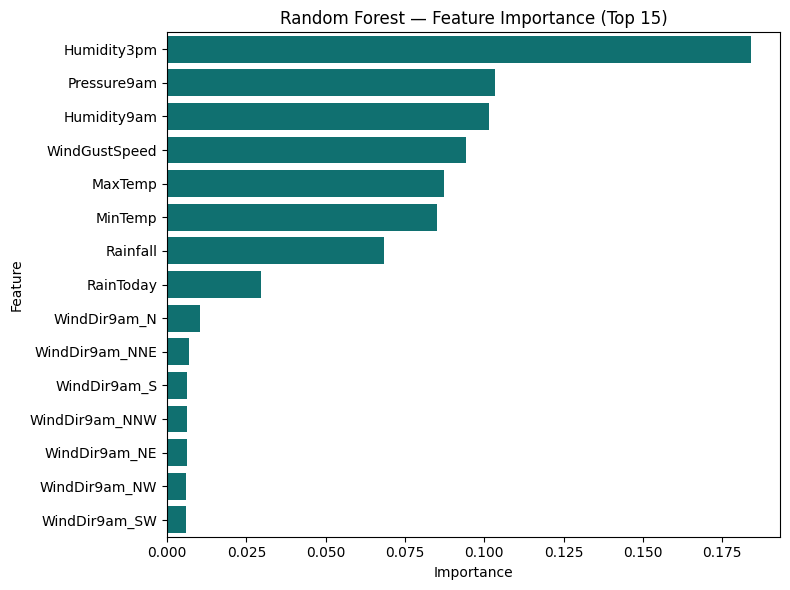

In [ ]:
# Tree-based models give feature_importances_ directly.
# The tuned Random Forest is used to see which inputs it relied on most.
forest = best_models["Random Forest"].named_steps["model"]
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": forest.feature_importances_
}).sort_values("Importance", ascending=False)
importance.to_csv(OUTPUT_DIR / "feature_importance.csv", index=False)

print("\nRANDOM FOREST FEATURE IMPORTANCE (top 15):")
print(importance.head(15).round(4).to_string(index=False))

plt.figure(figsize=(8, 6))
sns.barplot(data=importance.head(15), x="Importance", y="Feature", color="teal")
plt.title("Random Forest — Feature Importance (Top 15)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "15_feature_importance.png", dpi=160)
plt.show()

## 11. DECISION MAKING / RECOMMENDATIONS

In [ ]:
best_row = results_df[results_df["Model"] == best_model_name].iloc[0]

print("\nDECISION MAKING")
print("Best model:", best_model_name)
print("Validation AUC:", round(best_row["Validation AUC"], 3))
print("Validation accuracy:", round(best_row["Accuracy"] * 100, 2), "%")
print("Recall (share of rainy days detected):", round(best_row["Recall"] * 100, 2), "%")
print("Precision (share of rain alerts that are correct):",
      round(best_row["Precision"] * 100, 2), "%")
print("Most important features:", importance["Feature"].head(5).tolist())

# Simple profile that supports the recommendations.
profile = X.copy()
profile["RainTomorrow"] = y
print("\nAverage of selected numerical features: dry (0) vs rainy (1) next day")
selected_numeric = [c for c in numerical_columns if c in chosen_features]
print(profile.groupby("RainTomorrow")[selected_numeric].mean().round(2).T)

print("\nRECOMMENDATIONS:")
print("- Use", best_model_name, "to give a daily 'rain tomorrow' alert from")
print("  today's measurements.")
print("- Afternoon humidity, pressure and wind gust speed are the key warning")
print("  signs: high 3pm humidity, low pressure and strong gusts mean rain is")
print("  more likely.")
print("- Balancing the training data makes the model catch many more rainy days")
print("  (higher recall), at the cost of some false alarms (lower precision).")
print("- Users who must not miss rain (farmers, events, construction, airports)")
print("  can lower THRESHOLD to catch even more rainy days; users who dislike")
print("  false alarms can raise it.")
print("- Limitation: columns with too much missing data (sunshine, evaporation,")
print("  clouds) were removed; better data collection would improve the model.")

print("\nAll plots and tables saved in:", OUTPUT_DIR.resolve())


DECISION MAKING
Best model: SVM
Validation AUC: 0.86
Validation accuracy: 79.18 %
Recall (share of rainy days detected): 77.03 %
Precision (share of rain alerts that are correct): 52.43 %
Most important features: ['Humidity3pm', 'Pressure9am', 'Humidity9am', 'WindGustSpeed', 'MaxTemp']

Average of selected numerical features: dry (0) vs rainy (1) next day
RainTomorrow         0        1
MinTemp          11.89    13.09
MaxTemp          23.79    21.10
Rainfall          1.28     6.02
WindGustSpeed    38.29    45.51
Humidity9am      66.37    77.96
Humidity3pm      46.76    67.75
Pressure9am    1018.55  1014.82

RECOMMENDATIONS:
- Use SVM to give a daily 'rain tomorrow' alert from
  today's measurements.
- Afternoon humidity, pressure and wind gust speed are the key warning
  signs: high 3pm humidity, low pressure and strong gusts mean rain is
  more likely.
- Balancing the training data makes the model catch many more rainy days
  (higher recall), at the cost of some false alarms (lower p